# CricketIQ — Exploratory Data Analysis

EDA of the ICC World Cup / Champions Trophy player archive, the curated recommender set and tournament history.

**Run:** open from the `eda/` folder (or repo root) and execute all cells. Requires `pandas numpy matplotlib seaborn scikit-learn`.

| Dataset | Size | Source | Use |
|---|---|---|---|
| `icc_all_players.json` | 1,162 players · 1,684 player-event rows | Computed from Cricsheet ball-by-ball (528 men's matches; qualifiers excluded) | ICC archive page |
| `players.json` | 104 curated players | Hand-curated career profiles | Recommender / CRIC-SELECT |
| `tournaments.json` | 31 editions | ICC records | Hall of Fame |

**Data quality:** 0 missing values and 0 duplicate player ids in the archive. Cricsheet is missing a few historical matches, so some totals are slightly below official records (e.g. Kohli: 35 ODI WC matches vs 37 official). Names are Cricsheet short names ("V Kohli").

## Setup

In [ ]:
import json, os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'eda' else os.getcwd()
DATA = os.path.join(ROOT, "frontend", "lib", "data")
FIG = os.path.join(ROOT, "eda", "figures")
os.makedirs(FIG, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 130, "axes.titleweight": "bold", "savefig.bbox": "tight"})
EV = {"odi": "ODI World Cup", "t20": "T20 World Cup", "ct": "Champions Trophy"}
S = {}

def save(name):
    plt.savefig(os.path.join(FIG, name)); plt.show()

## Load data

In [ ]:
raw = json.load(open(os.path.join(DATA, "icc_all_players.json")))
rows = []
for p in raw:
    for k, ev in EV.items():
        if k in p:
            rows.append({"id": p["id"], "name": p["name"], "country": p["country"], "event": ev, **p[k]})
df = pd.DataFrame(rows).rename(columns={"m": "matches", "inn": "innings", "w": "wickets", "ct": "catches", "st": "stumpings"})
df["50"], df["100"] = df["50"].astype(int), df["100"].astype(int)
S["players"] = len(raw); S["player_event_rows"] = len(df)
S["rows_per_event"] = df.event.value_counts().to_dict()

## Data quality

In [ ]:
S["missing_values"] = int(df.isna().sum().sum())
S["duplicate_ids"] = int(pd.Series([p["id"] for p in raw]).duplicated().sum())
bat = df[df.innings >= 5]
bowl = df[df.wickets >= 5]

## Coverage

- ODI WC has the most players (716), then T20 WC (515), Champions Trophy (453).
- England (86), Pakistan (83), West Indies (79), Sri Lanka (77) and Australia (75) field the most distinct players — long-running teams with high squad turnover.

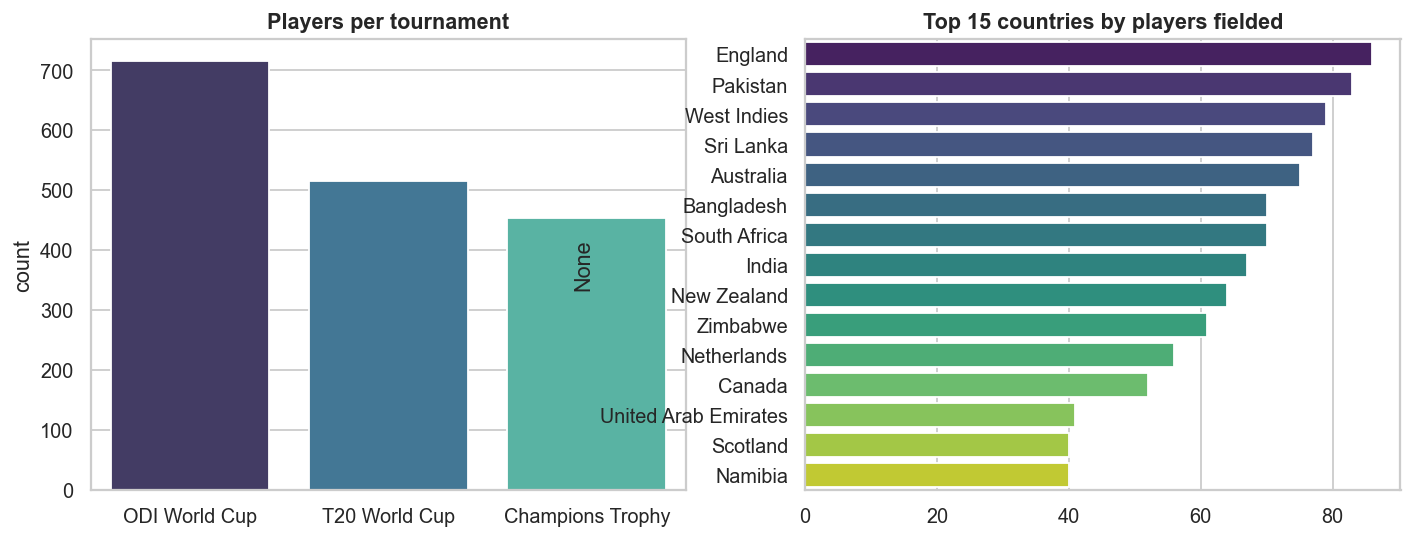

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=df, x="event", order=list(EV.values()), hue="event", palette="mako", legend=False, ax=ax[0])
ax[0].set_title("Players per tournament"); ax[0].set_xlabel("")
top = pd.Series([p["country"] for p in raw]).value_counts().head(15)
sns.barplot(x=top.values, y=top.index, hue=top.index, palette="viridis", legend=False, ax=ax[1]); ax[1].set_title("Top 15 countries by players fielded")
save("01_coverage.png")
S["top_countries"] = top.head(5).to_dict()

## Batting distributions

- Runs are heavily right-skewed: most players score little, a handful score thousands.
- Format drives the shape of the data (see §4); mixing formats without normalising would bias any model.

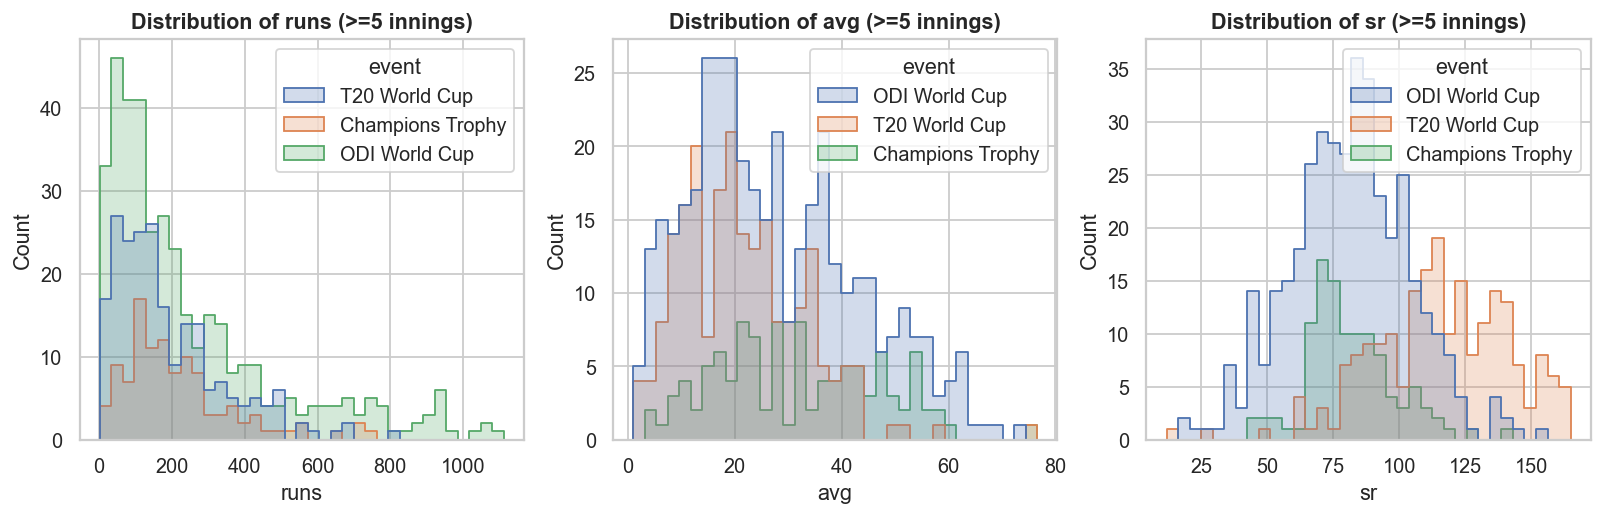

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, ["runs", "avg", "sr"]):
    sns.histplot(data=bat[bat[c] < bat[c].quantile(0.99)], x=c, hue="event", bins=35, element="step", ax=a)
    a.set_title(f"Distribution of {c} (>=5 innings)")
save("02_batting_distributions.png")

## Format effect

| Metric (median, ≥5 inn / ≥20 ov) | ODI WC | T20 WC | Champions Trophy |
|---|---|---|---|
| Strike rate | 82.0 | 116.6 | 78.8 |
| Batting average | 24.8 | 20.0 | 31.5 |
| Bowling economy | 5.23 | 7.56 | 4.80 |

**Insight:** T20 strike rates are ~42% higher than ODI while averages are lower — scoring is faster but less sustained. Champions Trophy has the highest averages and lowest economy, reflecting a small field of top teams and fewer weak-opposition matches.
→ *The recommender scores players per format and uses format-specific weights for this reason.*

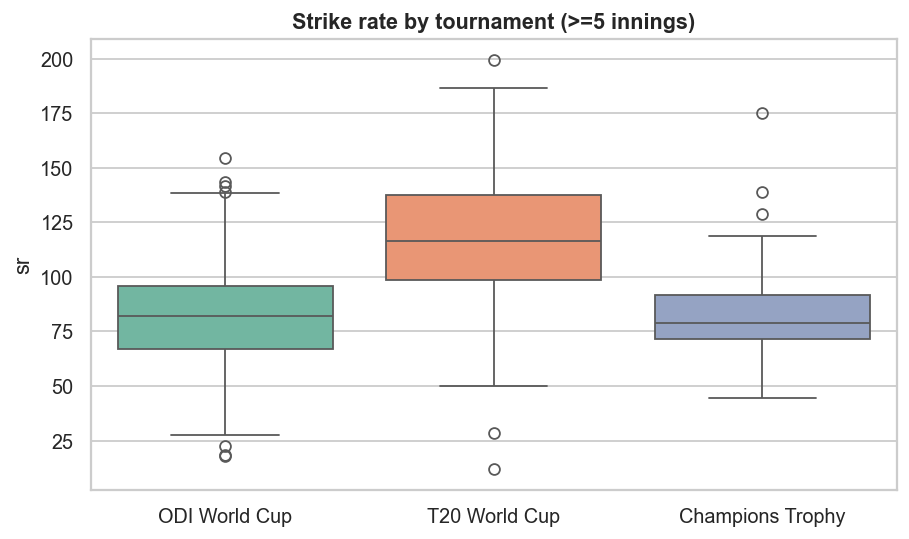

In [ ]:
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=bat[bat.sr < 250], x="event", y="sr", order=list(EV.values()), hue="event", palette="Set2", legend=False)
plt.title("Strike rate by tournament (>=5 innings)"); plt.xlabel("")
save("03_sr_by_event.png")
S["median_sr"] = bat.groupby("event").sr.median().round(1).to_dict()
S["median_avg"] = bat.groupby("event").avg.median().round(1).to_dict()

## Average vs strike rate

- Two clear clusters: ODI/CT batters (SR 70–110, avg 30–65) and T20 batters (SR 120–180, avg 15–45).
- The upper-right outliers (e.g. AB de Villiers, RG Sharma) combine both — the "elite" quadrant used by the app's scatter plot.
- Correlation between average and strike rate is only **0.25**, so they are genuinely different skills.

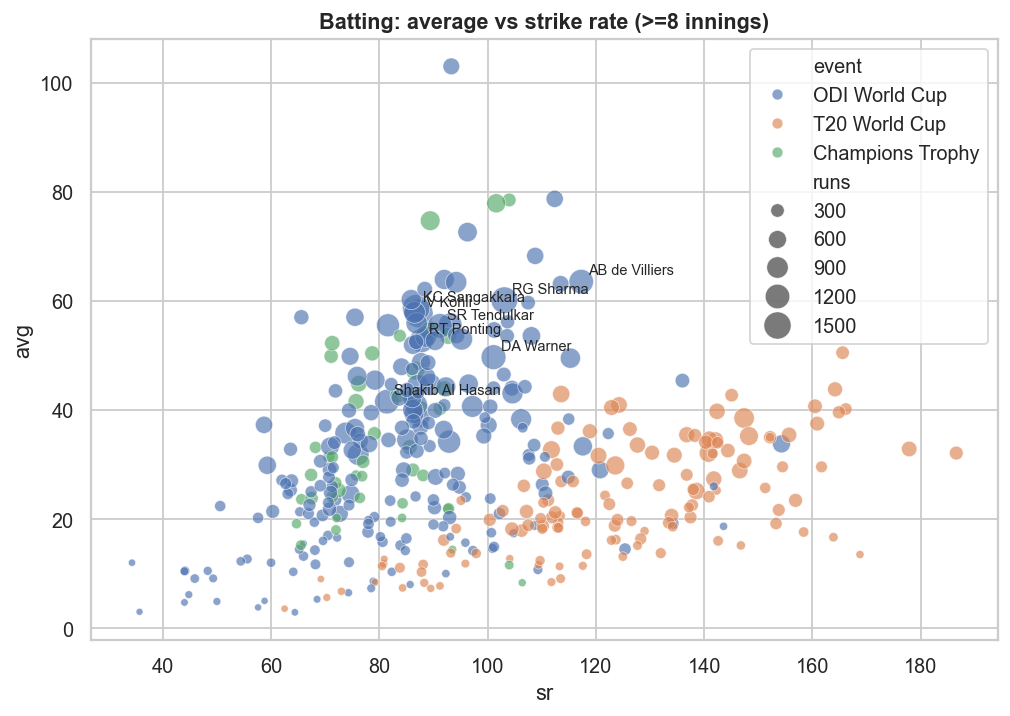

In [ ]:
plt.figure(figsize=(9, 6))
q = bat[(bat.innings >= 8) & (bat.sr < 250) & (bat.avg < 120)]
sns.scatterplot(data=q, x="sr", y="avg", hue="event", size="runs", sizes=(15, 250), alpha=.65)
for _, r in q.nlargest(8, "runs").iterrows():
    plt.annotate(r["name"], (r.sr, r.avg), fontsize=8, xytext=(4, 4), textcoords="offset points")
plt.title("Batting: average vs strike rate (>=8 innings)")
save("04_avg_vs_sr.png")

## Top performers

- Runs: V Kohli 2,911 · RG Sharma 2,569 · KC Sangakkara 2,018 · KS Williamson 1,997 · CH Gayle 1,814.
- Wickets: MA Starc 84 · TA Boult 76 · SL Malinga 75 · Mohammed Shami 69 · JJ Bumrah 68.
- Volume stats favour players with long careers and many events; the model therefore blends volume with rate stats (avg/SR/economy).

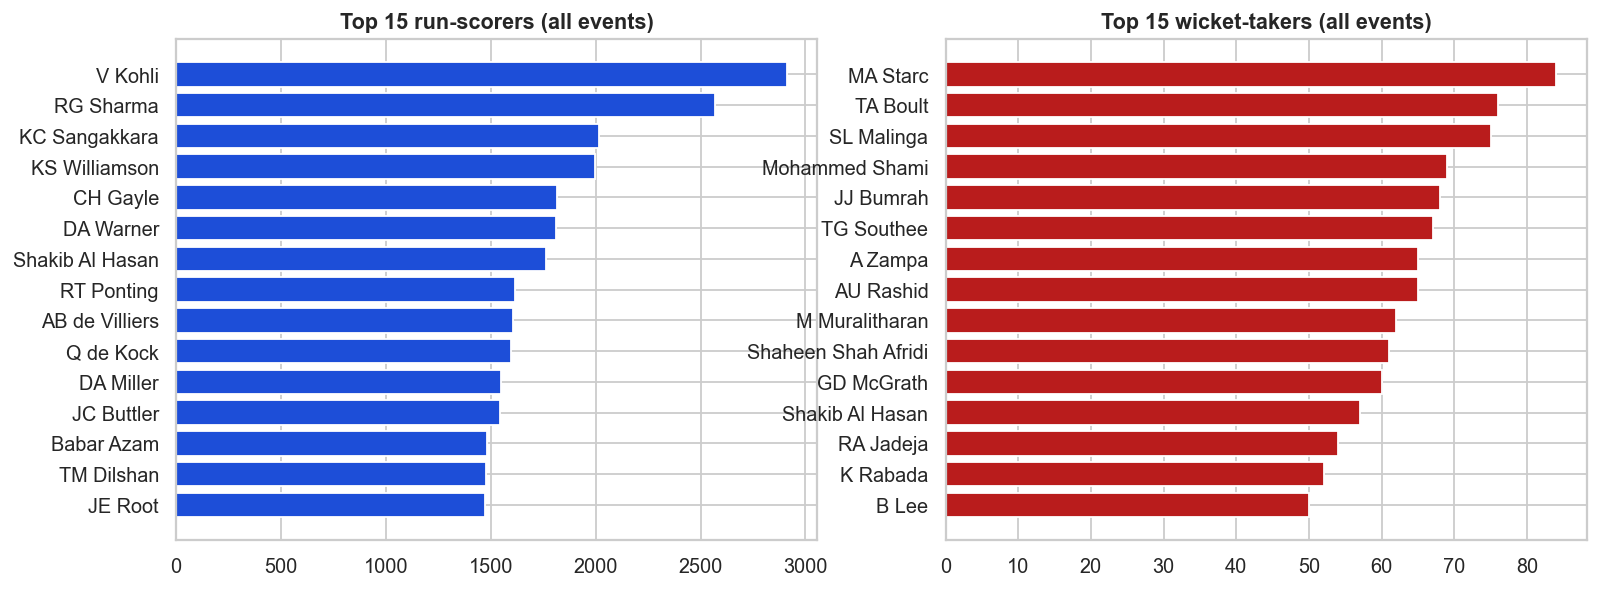

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
tr = df.groupby("name").runs.sum().nlargest(15)[::-1]
tw = df.groupby("name").wickets.sum().nlargest(15)[::-1]
ax[0].barh(tr.index, tr.values, color="#1d4ed8"); ax[0].set_title("Top 15 run-scorers (all events)")
ax[1].barh(tw.index, tw.values, color="#b91c1c"); ax[1].set_title("Top 15 wicket-takers (all events)")
save("05_top_performers.png")
S["top_run_scorers"] = tr[::-1].head(5).to_dict(); S["top_wicket_takers"] = tw[::-1].head(5).to_dict()

## Bowling

- Economy ordering mirrors batting: T20 ≫ ODI > CT. Wicket-takers sit mostly at economy 4.5–6.5 in 50-over events.

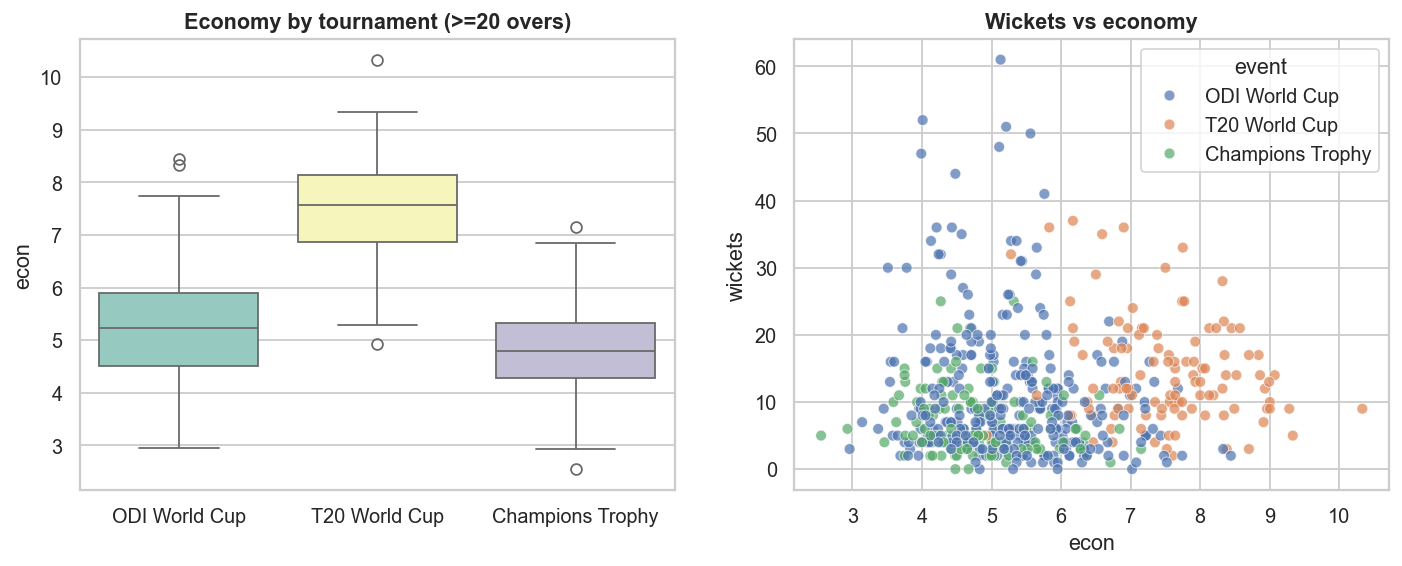

In [ ]:
bw = df[(df.ov >= 20)]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=bw[bw.econ < 12], x="event", y="econ", order=list(EV.values()), hue="event", palette="Set3", legend=False, ax=ax[0])
ax[0].set_title("Economy by tournament (>=20 overs)"); ax[0].set_xlabel("")
sns.scatterplot(data=bw[(bw.econ < 12)], x="econ", y="wickets", hue="event", alpha=.7, ax=ax[1])
ax[1].set_title("Wickets vs economy")
save("06_bowling.png")
S["median_econ"] = bw.groupby("event").econ.median().round(2).to_dict()

## Correlations

- Runs ↔ matches **0.65**: exposure is the strongest driver of totals — a reason to prefer per-match/rate features for fair comparison.
- Fifties/hundreds track runs very strongly (redundant for modelling); wickets are almost uncorrelated with runs (specialist split).

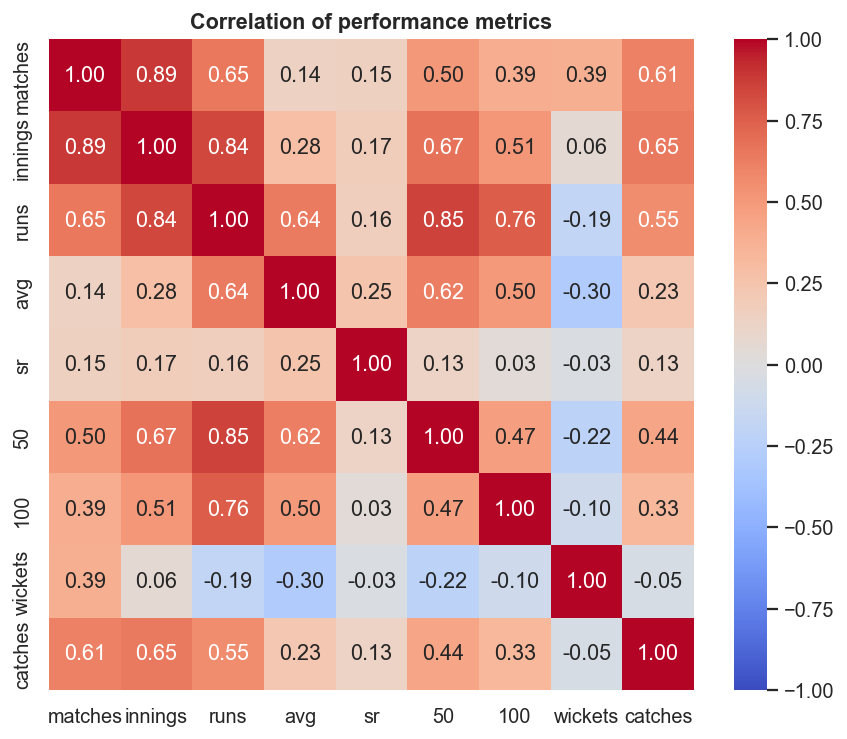

In [ ]:
num = bat[["matches", "innings", "runs", "avg", "sr", "50", "100", "wickets", "catches"]]
plt.figure(figsize=(8, 6.5)); sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation of performance metrics")
save("07_correlation.png")
S["corr_runs_matches"] = round(float(num.corr().loc["runs", "matches"]), 2)
S["corr_avg_sr"] = round(float(num.corr().loc["avg", "sr"]), 2)

## Player archetypes (unsupervised)

KMeans (k=5) on log-scaled runs, wickets, avg, SR, economy and catches for players with ≥8 matches, projected with PCA:

| Archetype | Players |
|---|---|
| All-rounders | 168 |
| Bowlers who bat a bit | 121 |
| Run machines | 86 |
| Middle-order batters | 85 |
| Pure bowlers | 13 |

The clusters line up with the roles used in the app (batter / all-rounder / bowler), supporting the role-aware scoring and "similar players" features.

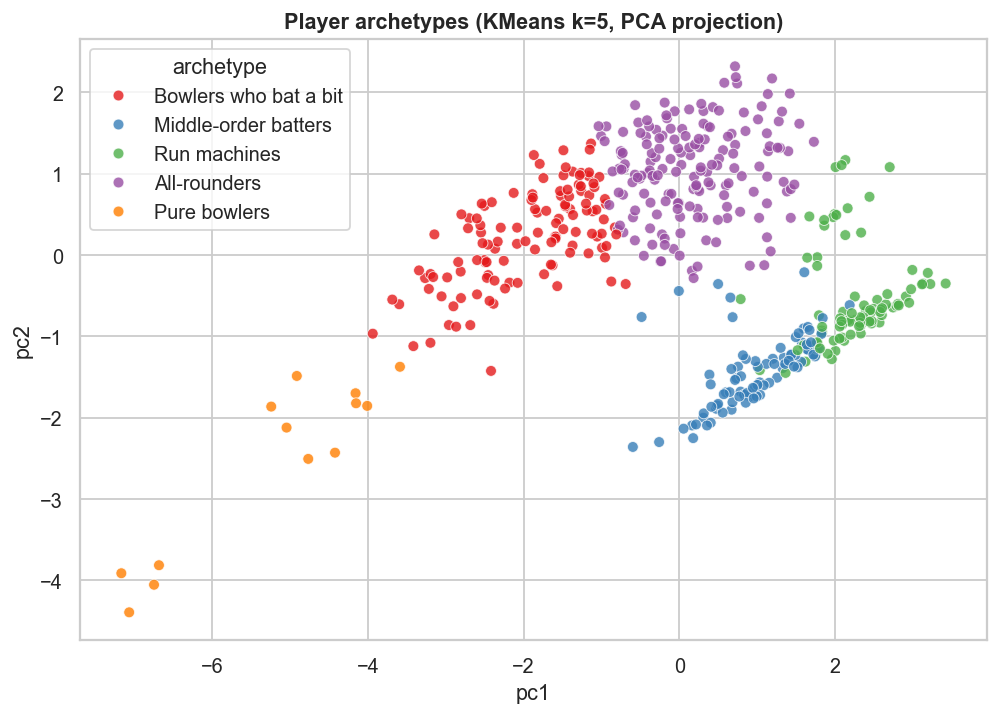

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
agg = df.groupby(["id", "name"]).agg(runs=("runs", "sum"), wk=("wickets", "sum"), inn=("innings", "sum"),
                                     avg=("avg", "mean"), sr=("sr", "mean"), econ=("econ", "mean"),
                                     ct=("catches", "sum"), m=("matches", "sum")).reset_index()
agg = agg[agg.m >= 8].copy()
X = StandardScaler().fit_transform(np.log1p(agg[["runs", "wk", "avg", "sr", "econ", "ct"]]))
agg["cluster"] = KMeans(n_clusters=5, n_init=10, random_state=42).fit_predict(X)
pc = PCA(2, random_state=42).fit_transform(X); agg["pc1"], agg["pc2"] = pc[:, 0], pc[:, 1]
prof = agg.groupby("cluster")[["runs", "wk", "avg", "sr", "econ", "ct"]].mean().round(1)
def label(r):
    if r.wk >= 10 and r.runs < 10: return "Pure bowlers"
    if r.wk >= 10 and r.runs < 150: return "Bowlers who bat a bit"
    if r.wk >= 10: return "All-rounders"
    if r.runs >= 600: return "Run machines"
    return "Middle-order batters"
names = {c: label(r) for c, r in prof.iterrows()}
agg["archetype"] = agg.cluster.map(names)
plt.figure(figsize=(9, 6)); sns.scatterplot(data=agg, x="pc1", y="pc2", hue="archetype", palette="Set1", alpha=.8)
plt.title("Player archetypes (KMeans k=5, PCA projection)")
save("08_archetypes.png")
S["archetype_sizes"] = agg.archetype.value_counts().to_dict()
S["cluster_profiles"] = prof.to_dict("index")

## Eras and trophies

- The player pool is dominated by post-2000 debutants (T20 WC and CT growth plus better ball-by-ball coverage).
- Titles: Australia 9, India 6, West Indies 5, England 3, Pakistan 3.

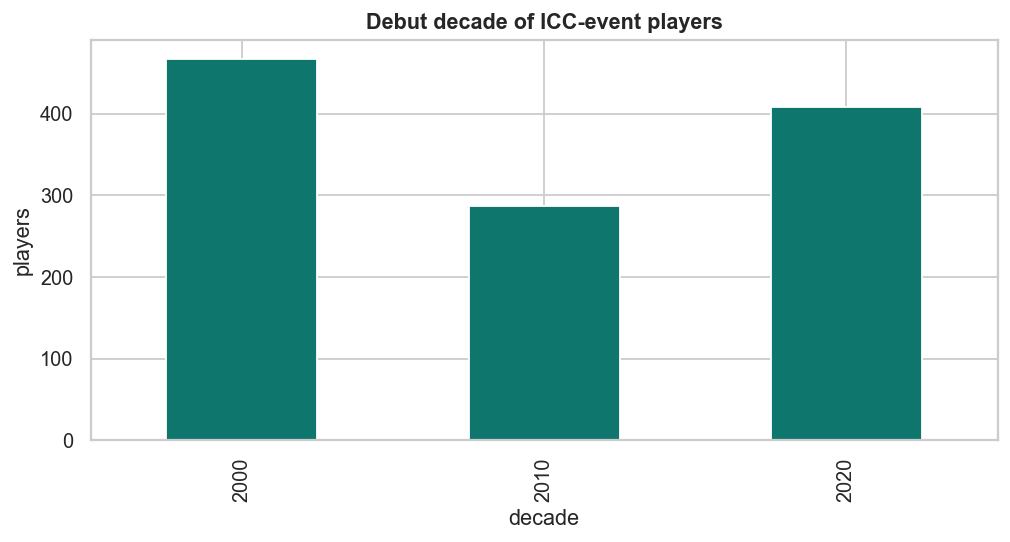

In [ ]:
yr = pd.DataFrame([{"year": int(p["years"][0]), "country": p["country"]} for p in raw if p.get("years")])
yr["decade"] = (yr.year // 10) * 10
plt.figure(figsize=(9, 4)); yr.decade.value_counts().sort_index().plot.bar(color="#0f766e")
plt.title("Debut decade of ICC-event players"); plt.xlabel("decade"); plt.ylabel("players")
save("09_debut_decades.png")

## Tournament titles

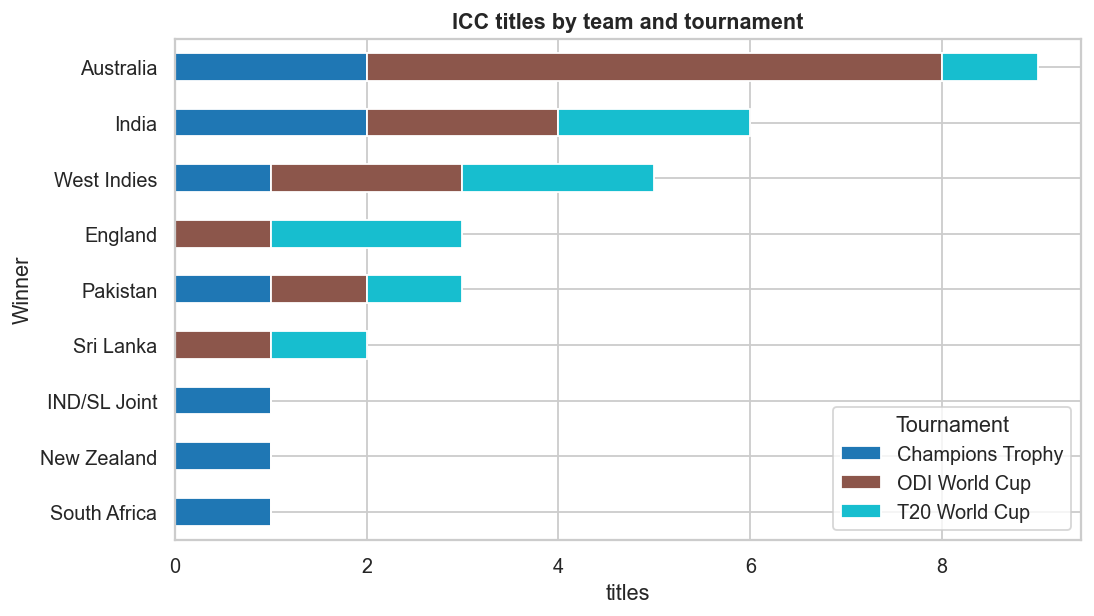

In [ ]:
t = pd.DataFrame(json.load(open(os.path.join(DATA, "tournaments.json"))))
w = t.groupby(["Winner", "Tournament"]).size().unstack(fill_value=0)
w = w.loc[w.sum(axis=1).sort_values(ascending=False).index]
w.plot.barh(stacked=True, figsize=(9, 5), colormap="tab10"); plt.gca().invert_yaxis()
plt.title("ICC titles by team and tournament"); plt.xlabel("titles")
save("10_titles.png")
S["title_leaders"] = w.sum(axis=1).head(5).to_dict()

## Curated recommender set

- 104 players: 31 all-rounders, 30 bowlers, 28 batters, 15 keeper-batters — a balanced pool for XI selection.

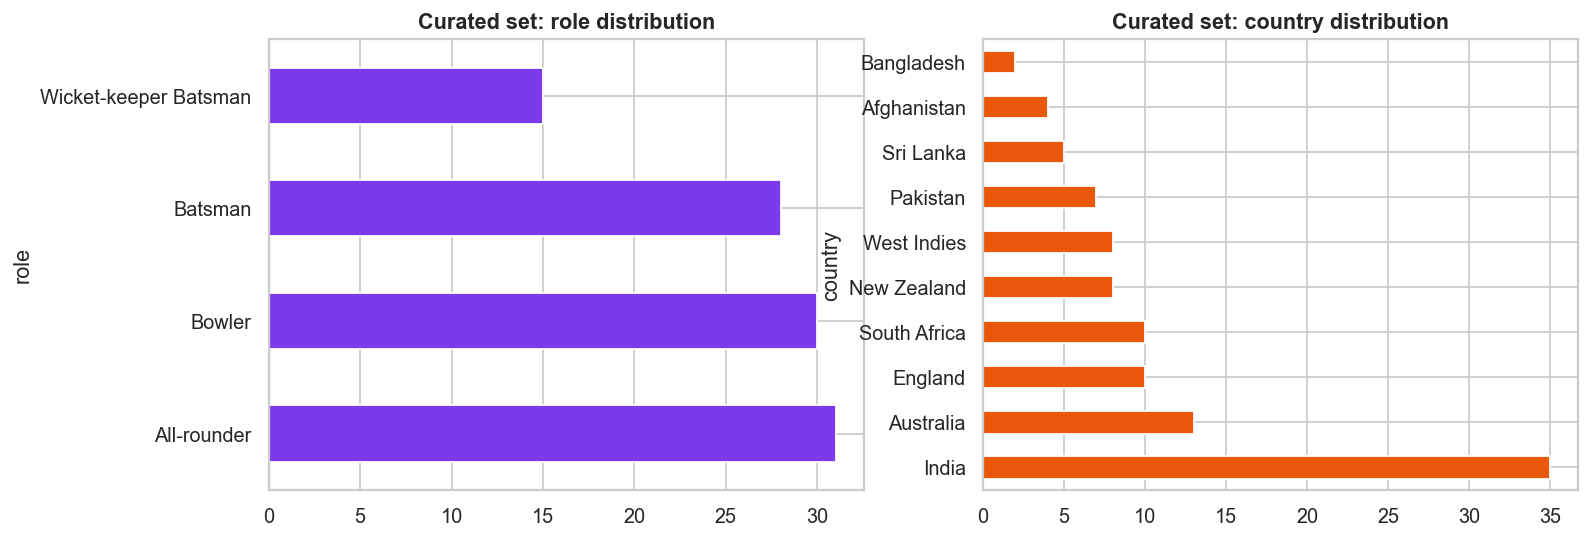

In [ ]:
cur = pd.DataFrame(json.load(open(os.path.join(DATA, "players.json"))))
S["curated_players"] = len(cur); S["curated_roles"] = cur.role.value_counts().to_dict()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
cur.role.value_counts().plot.barh(ax=ax[0], color="#7c3aed"); ax[0].set_title("Curated set: role distribution")
cur.country.value_counts().head(10).plot.barh(ax=ax[1], color="#ea580c"); ax[1].set_title("Curated set: country distribution")
save("11_curated_set.png")

## Concentration of performance

- The top 10% of players account for **55.9%** of all runs — a few stars carry most output, so shortlist quality matters more than breadth.

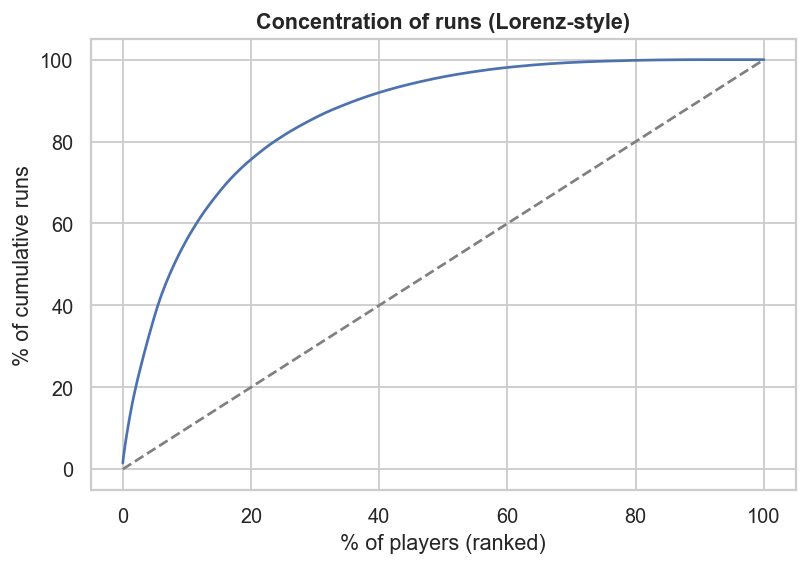

In [ ]:
share = (df.groupby("id").runs.sum().sort_values(ascending=False))
S["top10pct_run_share"] = round(float(share.head(int(len(share) * .1)).sum() / share.sum()), 3)
plt.figure(figsize=(7, 4.5)); c = share.cumsum() / share.sum()
plt.plot(np.linspace(0, 100, len(c)), c.values * 100); plt.plot([0, 100], [0, 100], "--", color="gray")
plt.title("Concentration of runs (Lorenz-style)"); plt.xlabel("% of players (ranked)"); plt.ylabel("% of cumulative runs")
save("12_run_concentration.png")

json.dump(S, open(os.path.join(ROOT, "eda", "summary.json"), "w"), indent=2, default=str)
S

## Takeaways for the model

1. Normalise per format; never compare raw SR/economy across T20 and ODI.
2. Use rate stats (avg, SR, economy) plus a capped volume term to avoid rewarding sheer longevity.
3. Keep roles distinct — wickets and runs are nearly independent skills.
4. Small-sample players (<5 innings) are noisy; the archive page and EDA apply minimum-innings filters.
5. Extend the recommender to the 1,162-player archive using the same features.